# Лабораторная № 1. Регрессия
**Темников Дмитрий Павлович, М8О-306БВ-24**

Предсказываем `quality` по химическим характеристикам вина. Используем общий набор red + white: 6497 строк, 11 измерений и `wine_type` (0 — red, 1 — white).

[Задание](https://github.com/lesopylka/ml_course_mai/blob/main/regression/lab01.pdf) · [Данные UCI, Cortez et al. (2009), CC BY 4.0](https://archive.ics.uci.edu/dataset/186/wine+quality).

In [ ]:
%pip install -q numpy pandas matplotlib seaborn "scikit-learn>=1.6"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

SEED = 26

## 1. Данные и разбиение
`quality` — ответ, остальные столбцы — признаки. Тип вина добавляем до объединения строк.

In [3]:
red = pd.read_csv('data/winequality-red.csv', sep=';')
white = pd.read_csv('data/winequality-white.csv', sep=';')
red['wine_type'] = 0
white['wine_type'] = 1
data = pd.concat([red, white], ignore_index=True)
print('Размер:', data.shape)
print('Пропуски:', data.isna().sum().sum())
print('Полные повторы:', data.duplicated().sum())
display(data.head())

Размер: (6497, 13)
Пропуски: 0
Полные повторы: 1177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


Пропусков нет. 1177 повторов сохраняем: неизвестно, являются ли они ошибкой копирования или отдельными наблюдениями. Одинаковые признаки объединяем в группы и не разделяем между обучением и проверкой.

Примерно 80% групп используем для обучения, 20% — для локального теста. Точный размер частей зависит от размеров групп. `SEED = 26` позволяет повторить разбиение.

In [4]:
X = data.drop(columns='quality')
y = data['quality']
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(split.split(X, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
print('Train:', len(X_train), 'Test:', len(X_test))

Train: 5165 Test: 1332


## 2. Анализ обучающей части
Смотрим диапазоны признаков, частоты оценок и распределения. Тест для исследовательского анализа не используем.

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5165.0,7.23,1.33,3.80,6.40,7.00,7.70,15.90
volatile acidity,5165.0,0.34,0.16,0.08,0.23,0.29,0.40,1.58
citric acid,5165.0,0.32,0.14,0.00,0.25,0.31,0.40,1.66
residual sugar,5165.0,5.40,4.69,0.60,1.80,3.00,8.00,31.60
chlorides,5165.0,0.06,0.03,0.01,0.04,0.05,0.06,0.61
free sulfur dioxide,5165.0,30.50,17.87,1.00,17.00,29.00,41.00,289.00
total sulfur dioxide,5165.0,115.67,56.87,6.00,77.00,118.00,156.00,440.00
density,5165.0,0.99,0.00,0.99,0.99,0.99,1.00,1.01
pH,5165.0,3.22,0.16,2.72,3.11,3.21,3.32,4.01
sulphates,5165.0,0.53,0.15,0.22,0.43,0.51,0.60,2.00


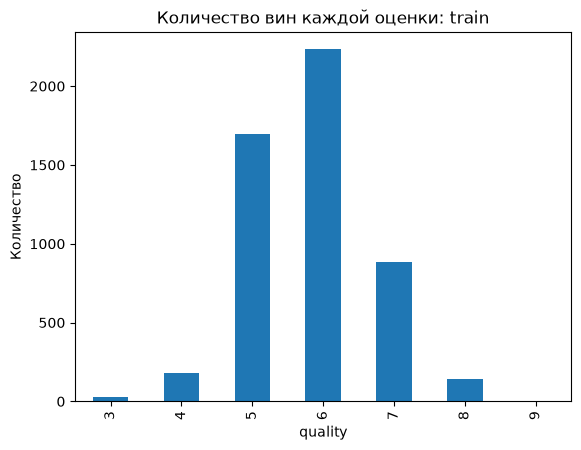

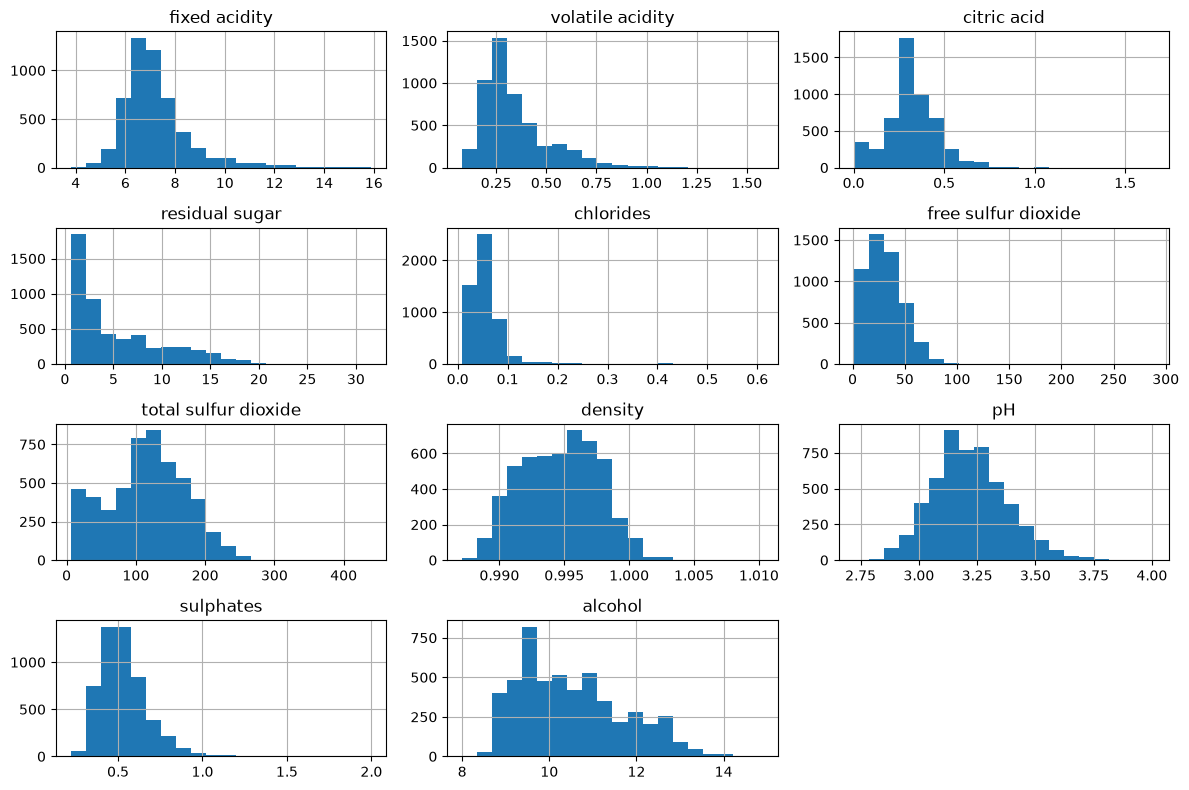

In [5]:
train = X_train.assign(quality=y_train)
display(train.describe().T.round(2))
y_train.value_counts().sort_index().plot.bar(title='Количество вин каждой оценки: train')
plt.xlabel('quality')
plt.ylabel('Количество')
plt.show()
X_train.drop(columns='wine_type').hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

density                -0.311
volatile acidity       -0.264
chlorides              -0.205
fixed acidity          -0.087
total sulfur dioxide   -0.052
residual sugar         -0.038
sulphates               0.039
free sulfur dioxide     0.040
pH                      0.044
citric acid             0.077
wine_type               0.121
alcohol                 0.444
Name: quality, dtype: float64

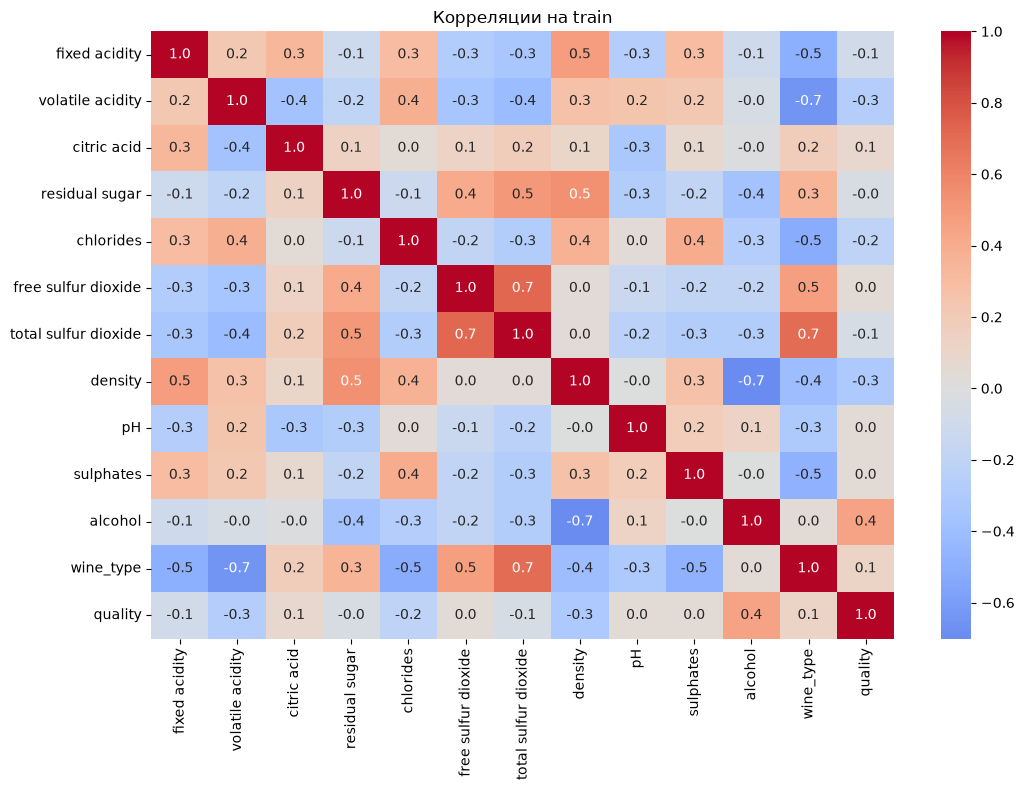

In [6]:
correlations = train.corr()
display(correlations['quality'].drop('quality').sort_values().round(3))
plt.figure(figsize=(11, 8))
sns.heatmap(correlations, cmap='coolwarm', center=0, annot=True, fmt='.1f')
plt.title('Корреляции на train')
plt.tight_layout()
plt.show()

Большинство оценок — 5 и 6, крайние значения редки. Модели будет сложнее обучиться на редких примерах. У некоторых концентраций есть длинные правые хвосты; большие значения сами по себе не доказывают ошибку измерения, поэтому их не удаляем.

`alcohol` положительно связан с качеством, `density` и `volatile acidity` — отрицательно. Это полезные предикторы, но корреляция не доказывает причину. Общие связи могут частично отражать различия red/white. Сохраняем все признаки: слабая корреляция не исключает нелинейной зависимости.

## 3. Модели и сравнение
**MAE** — средний модуль ошибки. **RMSE** — корень из средней квадратичной ошибки; сильнее учитывает крупные промахи. Обе метрики измеряются в баллах quality, меньше — лучше.

$$MAE=\frac{1}{n}\sum_{i=1}^n |y_i-\hat y_i|,\qquad RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^n(y_i-\hat y_i)^2}.$$

- **Baseline** всем предсказывает среднее обучающих ответов. Эта константа оптимальна для RMSE; для MAE оптимальна медиана.
- **Линейная регрессия** складывает взвешенные признаки. `StandardScaler` внутри Pipeline нужен для сравнения коэффициентов в сопоставимых единицах. Он обучается только на train каждого фолда.
- **Lasso (L1)** — линейная регрессия со штрафом за сумму модулей коэффициентов. Может обнулять коэффициенты и исключать часть признаков.
- **Ridge (L2)** — линейная регрессия со штрафом за сумму квадратов коэффициентов. Уменьшает коэффициенты, обычно без обнуления.
- **Случайный лес** усредняет 400 деревьев. `max_features=0.5` означает случайный выбор половины признаков при поиске разбиения. Настройки найдены ранее по train CV.
- **Бустинг** последовательно добавляет деревья, исправляющие ошибки текущего прогноза. Небольшой `learning_rate` ограничивает размер поправки.

У Lasso и Ridge параметр `alpha` задаёт силу штрафа: больше `alpha` — сильнее ограничение коэффициентов. Слишком сильный штраф может привести к недообучению. Для сравнения заранее фиксируем `alpha=0.01` у Lasso и `alpha=1.0` у Ridge; эти числа нельзя напрямую сравнивать между алгоритмами. По test их не подбираем.

In [7]:
models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Lasso (L1)': make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=10000)),
    'Ridge (L2)': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Random Forest': RandomForestRegressor(n_estimators=400, max_features=0.5,
        min_samples_leaf=1, random_state=SEED, n_jobs=2),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=400,
        learning_rate=0.03, max_depth=3, min_samples_leaf=4, random_state=SEED)
}

CV (cross-validation, кросс-валидация) — повторная проверка на частях обучающей выборки. Делим train на пять групповых фолдов: учим модель на четырёх, проверяем на пятом, затем меняем проверочную часть. Средняя ошибка пяти проверок — CV RMSE. Одинаковые строки не разделяем между обучением и проверкой. Все шесть решений используют одни и те же разбиения. Модель выбираем по минимальной CV RMSE.

In [8]:
cv = list(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
    X_train, y_train, groups[train_idx]))
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
        scoring='neg_root_mean_squared_error', return_train_score=True)
    cv_rows.append({'Model': name, 'Train RMSE': -scores['train_score'].mean(),
                   'CV RMSE': -scores['test_score'].mean()})
cv_table = pd.DataFrame(cv_rows).set_index('Model')
display(cv_table.round(4))
best_name = cv_table['CV RMSE'].idxmin()
print('Выбрана по CV:', best_name)

,Train RMSE,CV RMSE
Model,,
Baseline,0.8781,0.8780
Linear Regression,0.7359,0.7412
Lasso (L1),0.7413,0.7462
Ridge (L2),0.7359,0.7412
Random Forest,0.2206,0.6938
Gradient Boosting,0.6211,0.7101


Выбрана по CV: Random Forest


Лес лучше по CV, но у него заметный разрыв между train и CV: модель очень гибкая и частично переобучается. Его нелинейные зависимости и взаимодействия признаков дают преимущество перед простой линейной моделью.

Параметры леса уже выбирались по этим фолдам, поэтому минимум CV может быть оптимистичным. Ранее процедура подбора отдельно проверена вложенной CV: средняя внешняя RMSE — **0.6937**.

Теперь оцениваем все модели на общем локальном test. Он уже открывался в прошлой версии, поэтому повторная оценка диагностическая. По ответам test модель и параметры не выбираем; многократный подбор по test сделал бы его частью обучения.

In [9]:
test_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    test_rows.append({'Model': name, 'RMSE': root_mean_squared_error(y_test, prediction),
                      'MAE': mean_absolute_error(y_test, prediction)})
test_table = pd.DataFrame(test_rows).set_index('Model')
display(test_table.round(4))
best_model = models[best_name]

,RMSE,MAE
Model,,
Baseline,0.8539,0.6674
Linear Regression,0.7193,0.5570
Lasso (L1),0.7166,0.5536
Ridge (L2),0.7192,0.5569
Random Forest,0.6413,0.5011
Gradient Boosting,0.6682,0.5254


## 4. Коэффициенты линейных моделей: обычная, L1 и L2
Коэффициент показывает изменение прогноза при увеличении признака на одно стандартное отклонение, если остальные признаки фиксированы. Для обычной линейной регрессии со свободным членом масштабирование обычно сохраняет прогнозы, но меняет единицы коэффициентов.

Сравним коэффициенты трёх моделей. У Lasso некоторые из них могут стать нулевыми, у Ridge они обычно уменьшаются по общей величине. Отдельные коэффициенты могут меняться иначе из-за связанных признаков.

,Linear Regression,Lasso (L1),Ridge (L2)
fixed acidity,0.150,-0.000,0.149
volatile acidity,-0.243,-0.223,-0.243
citric acid,-0.009,-0.000,-0.009
residual sugar,0.354,0.095,0.352
chlorides,-0.023,-0.020,-0.023
free sulfur dioxide,0.075,0.059,0.075
total sulfur dioxide,-0.079,-0.079,-0.079
density,-0.408,-0.006,-0.405
pH,0.119,0.032,0.118
sulphates,0.113,0.079,0.113


Нулевых коэффициентов Lasso: 2


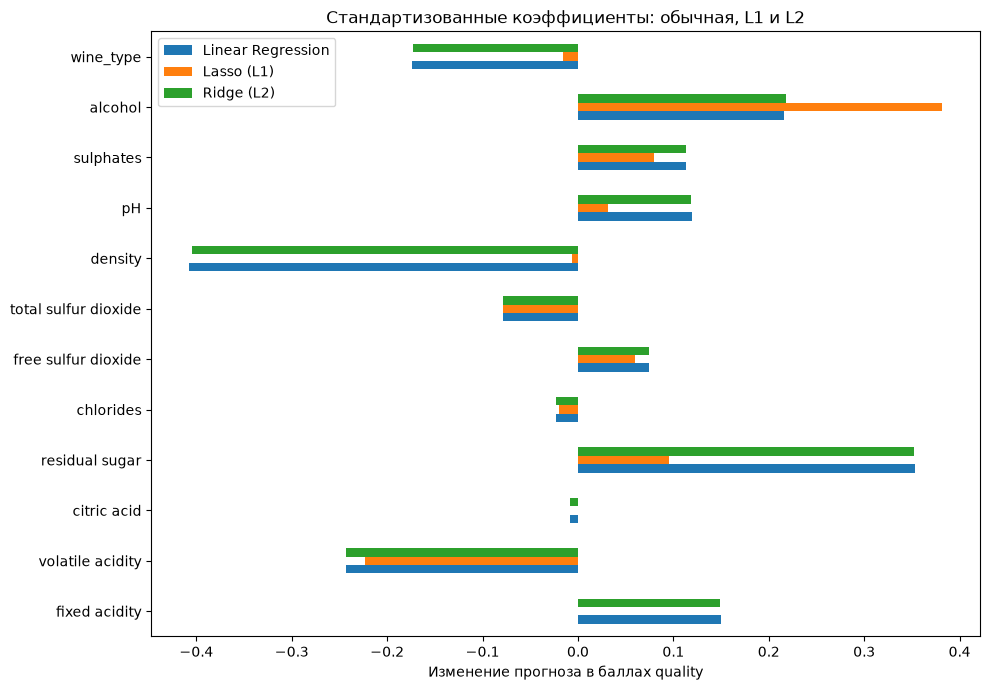

In [10]:
linear_names = ['Linear Regression', 'Lasso (L1)', 'Ridge (L2)']
coefficients = pd.DataFrame({name: models[name].steps[-1][1].coef_
                             for name in linear_names}, index=X.columns)
display(coefficients.round(3))
print('Нулевых коэффициентов Lasso:', (coefficients['Lasso (L1)'].abs() < 1e-8).sum())
coefficients.plot.barh(figsize=(10, 7), title='Стандартизованные коэффициенты: обычная, L1 и L2')
plt.xlabel('Изменение прогноза в баллах quality')
plt.tight_layout()
plt.show()

У обычной линейной регрессии наибольшие по модулю коэффициенты у density, residual sugar и volatile acidity. Коэффициенты учитывают другие признаки, поэтому могут отличаться от парных корреляций. Связанные между собой признаки делают интерпретацию отдельных коэффициентов менее устойчивой.

При выбранных alpha Lasso обнулил коэффициенты `fixed acidity` и `citric acid`. Ridge сохранил все 12 коэффициентов и дал результат, близкий к обычной регрессии. По CV Lasso получил RMSE 0.7462, Ridge — 0.7412, обычная регрессия — 0.7412. Регуляризация ограничила коэффициенты, но при этих настройках не дала существенного улучшения качества.

## 5. Важность признаков деревьев
`feature_importances_` показывает вклад разбиений по признаку в снижение ошибки. Внутри модели важности суммируются до 1. Это характеристика модели; связанные признаки могут делить вклад.

Random Forest — top-3: ['alcohol', 'volatile acidity', 'density']
Gradient Boosting — top-3: ['alcohol', 'volatile acidity', 'free sulfur dioxide']


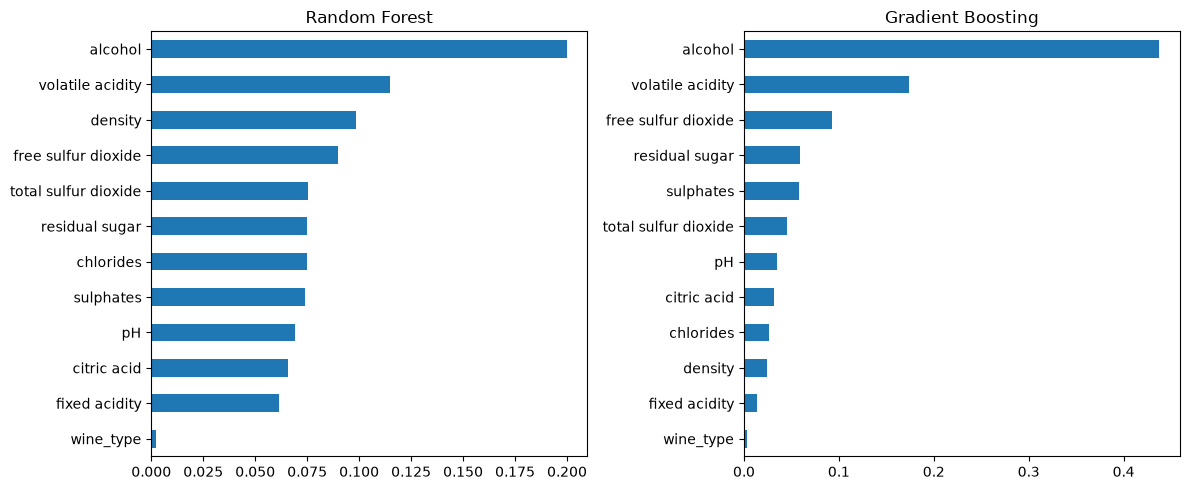

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, ax in zip(['Random Forest', 'Gradient Boosting'], axes):
    importance = pd.Series(models[name].feature_importances_, index=X.columns).sort_values()
    importance.plot.barh(ax=ax, title=name)
    print(name, '— top-3:', importance.nlargest(3).index.tolist())
plt.tight_layout()
plt.show()

В обоих ансамблях важен alcohol, что согласуется с анализом корреляций. В top-3 леса также density и volatile acidity, у бустинга — volatile acidity и free sulfur dioxide. Разные алгоритмы используют признаки по-разному.

Важность не доказывает причинность: например, из важности alcohol не следует, что добавление спирта улучшит вино. Данные наблюдательные, некоторые факторы не измерены.

## 6. Ошибки лучшей модели
Остаток = истинная оценка − прогноз. Положительный остаток означает недооценку. Посмотрим крупные ошибки, распределение остатков и близость прогнозов к истинным значениям.

,real,prediction,abs_error,alcohol,volatile acidity,free sulfur dioxide,wine_type
4008,4,6.260,2.260,10.2,0.21,23.0,1
4012,4,6.260,2.260,10.2,0.21,23.0,1
2426,9,6.780,2.220,12.5,0.24,27.0,1
5683,8,5.872,2.128,11.5,0.33,20.0,1
5060,8,5.878,2.122,11.3,0.24,105.0,1


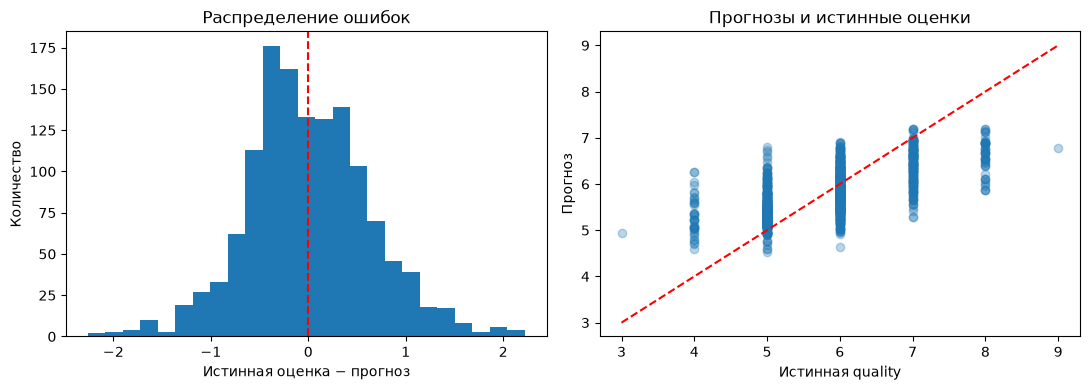

In [12]:
prediction = best_model.predict(X_test)
errors = X_test.assign(real=y_test, prediction=prediction, error=y_test - prediction)
errors['abs_error'] = errors['error'].abs()
columns = ['real', 'prediction', 'abs_error', 'alcohol', 'volatile acidity',
           'free sulfur dioxide', 'wine_type']
display(errors.nlargest(5, 'abs_error')[columns].round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(errors['error'], bins=25)
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set(title='Распределение ошибок', xlabel='Истинная оценка − прогноз', ylabel='Количество')
axes[1].scatter(y_test, prediction, alpha=0.3)
limits = [y.min(), y.max()]
axes[1].plot(limits, limits, 'r--')
axes[1].set(title='Прогнозы и истинные оценки', xlabel='Истинная quality', ylabel='Прогноз')
plt.tight_layout()
plt.show()

In [13]:
quality_rows = []
for quality, part in errors.groupby('real'):
    quality_rows.append({'quality': quality, 'count': len(part),
        'MAE': part['abs_error'].mean(), 'RMSE': np.sqrt((part['error'] ** 2).mean())})
display(pd.DataFrame(quality_rows).set_index('quality').round(3))

,count,MAE,RMSE
quality,,,
3,1,1.932,1.932
4,39,1.312,1.377
5,442,0.463,0.570
6,603,0.365,0.440
7,197,0.608,0.726
8,49,1.386,1.434
9,1,2.220,2.220


Строки 4008 и 4012 получили прогноз 6.26 вместо 4. У этих строк одинаковые признаки и ответ: одна и та же ошибка повторяется дважды. Химических измерений может быть недостаточно, чтобы объяснить низкую экспертную оценку.

## 7. Вывод
- Все пять обученных моделей лучше постоянного baseline на общем test.
- По train CV выбран случайный лес: **RMSE 0.6938**. Его локальные **RMSE 0.6413, MAE 0.5011**; у baseline RMSE 0.8539.
- L1 обнулил два коэффициента; L2 уменьшил общую величину коэффициентов. При выбранных alpha эти модели не превзошли лес.
- Нелинейные ансамбли лучше описали данные. Важность признаков согласуется с EDA.
- Крайние quality предсказываются хуже.